# 21 — Age-Overlap Validation

**Phase 21** found that a demographics-only classifier (Age / Gender / BMI) reaches
**AUC 0.978** — far above every thermal model tested (TCI-only 0.859, fusion 0.889) —
driven by an extreme age gap between Control (median 25.0) and DM (median 55.5) with
almost no overlap.

This notebook isolates the **"hard" subset** of subjects whose ages actually overlap
between the two groups — where a demographics-only classifier cannot trivially
separate them — and compares every model's performance specifically on that harder
subset.

If the thermal models hold up reasonably well there while the demographics-only
baseline collapses, that is strong, direct evidence the thermal signal captures
something genuinely diabetes-specific, not just an age proxy.

**No deep model is retrained here** — all thermal-model predictions are pooled
out-of-fold predictions already saved from earlier phases. Only the demographics-only
baseline's per-subject predictions are recomputed (Phase 21 only saved its AUC, not
the predictions).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

DATA_DIR = Path("data/processed")
RESULTS_DIR = Path("results")

## Section 1 — Setup

Load the four source files and merge them into a single 167-row DataFrame keyed on
`subject_id`, with columns: `subject_id, group, true_label, Age_years, BMI, gat_prob,
tci_prob, fusion_prob`.

- `gat_prob` <- `mc_mean_prob` from `cv_pooled_predictions.csv` (DualBranchGAT alone)
- `tci_prob` <- `LR_worse_foot_tci` from `baseline_pooled_predictions.csv`
- `fusion_prob` <- `fusion_b_prob` from `fusion_pooled_predictions.csv` (headline fusion model)

We also sanity-check that `group` / `true_label` agree across all three prediction
files before trusting anything downstream.

In [2]:
print("=" * 70)
print("SECTION 1: SETUP - FILE LOADING AND MERGE")
print("=" * 70)

meta = pd.read_csv(DATA_DIR / "subject_metadata.csv")
cv_pred = pd.read_csv(RESULTS_DIR / "cv_pooled_predictions.csv")
baseline_pred = pd.read_csv(RESULTS_DIR / "baseline_pooled_predictions.csv")
fusion_pred = pd.read_csv(RESULTS_DIR / "fusion_pooled_predictions.csv")

print(f"subject_metadata.csv            rows: {len(meta)}")
print(f"cv_pooled_predictions.csv       rows: {len(cv_pred)}")
print(f"baseline_pooled_predictions.csv rows: {len(baseline_pred)}")
print(f"fusion_pooled_predictions.csv   rows: {len(fusion_pred)}")

# Cross-file consistency check on group / true_label before merging
check = (
    cv_pred[["subject_id", "group", "true_label"]]
    .merge(baseline_pred[["subject_id", "group", "true_label"]],
           on="subject_id", suffixes=("_cv", "_baseline"))
    .merge(fusion_pred[["subject_id", "group", "true_label"]]
           .rename(columns={"group": "group_fusion", "true_label": "true_label_fusion"}),
           on="subject_id")
)
mismatch_group = check[(check["group_cv"] != check["group_baseline"]) |
                        (check["group_cv"] != check["group_fusion"])]
mismatch_label = check[(check["true_label_cv"] != check["true_label_baseline"]) |
                        (check["true_label_cv"] != check["true_label_fusion"])]
print(f"\nCross-file group mismatches:      {len(mismatch_group)}")
print(f"Cross-file true_label mismatches: {len(mismatch_label)}")
if len(mismatch_group) or len(mismatch_label):
    print("[WARNING] group/true_label are inconsistent across prediction files -- investigate before trusting results.")

meta_r = meta.rename(columns={"Subject": "subject_id"})

df = meta_r[["subject_id", "Gender", "Age_years", "BMI", "Group"]].merge(
    cv_pred[["subject_id", "group", "true_label", "mc_mean_prob"]],
    on="subject_id", how="inner", validate="one_to_one",
)
df = df.merge(
    baseline_pred[["subject_id", "LR_worse_foot_tci"]],
    on="subject_id", how="inner", validate="one_to_one",
)
df = df.merge(
    fusion_pred[["subject_id", "fusion_b_prob"]],
    on="subject_id", how="inner", validate="one_to_one",
)

df = df.rename(columns={
    "mc_mean_prob": "gat_prob",
    "LR_worse_foot_tci": "tci_prob",
    "fusion_b_prob": "fusion_prob",
})

# 'group' from cv_pred and 'Group' from subject_metadata should agree; keep 'group'.
group_mismatch = df[df["group"] != df["Group"]]
if len(group_mismatch):
    print(f"[WARNING] {len(group_mismatch)} subjects have mismatched group labels between "
          f"subject_metadata.csv and cv_pooled_predictions.csv")
df = df.drop(columns=["Group"])

df = df[["subject_id", "group", "true_label", "Age_years", "BMI", "gat_prob", "tci_prob", "fusion_prob"]]

n_expected = 167
status = "PASS" if len(df) == n_expected else "FAIL"
print(f"\nMerged dataframe rows: {len(df)}")
print(f"[{status}] Expected {n_expected}/{n_expected} matched subjects, got {len(df)}")
assert len(df) == n_expected, f"Merge produced {len(df)} rows, expected {n_expected}"

print("\nGroup -> true_label mapping check:")
label_map = df.groupby("group")["true_label"].unique()
print(label_map)

assert set(df["group"].unique()) == {"Control", "DM"}, f"Unexpected group values: {df['group'].unique()}"
dm_labels = df.loc[df["group"] == "DM", "true_label"].unique()
control_labels = df.loc[df["group"] == "Control", "true_label"].unique()
assert len(dm_labels) == 1 and len(control_labels) == 1, "true_label is not constant within a group -- check data"
DM_LABEL = int(dm_labels[0])
print(f"DM group corresponds to true_label = {DM_LABEL}")

display(df.head())

SECTION 1: SETUP - FILE LOADING AND MERGE
subject_metadata.csv            rows: 167
cv_pooled_predictions.csv       rows: 167
baseline_pooled_predictions.csv rows: 167
fusion_pooled_predictions.csv   rows: 167

Cross-file group mismatches:      0
Cross-file true_label mismatches: 0

Merged dataframe rows: 167
[PASS] Expected 167/167 matched subjects, got 167

Group -> true_label mapping check:
group
Control    [0]
DM         [1]
Name: true_label, dtype: object
DM group corresponds to true_label = 1


,subject_id,group,true_label,Age_years,BMI,gat_prob,tci_prob,fusion_prob
0,CG001,Control,0,25.0,20.006569,0.258263,0.091324,0.174794
1,CG002,Control,0,26.0,29.031790,0.508386,0.396369,0.452378
2,CG003,Control,0,24.0,21.258503,0.631612,0.793108,0.712360
3,CG004,Control,0,22.0,27.055151,0.142305,0.284608,0.213456
4,CG005,Control,0,38.0,24.034610,0.174862,0.125661,0.150262


## Section 2 — Find the Age-Overlap Range

Compute each group's `[min, max]` `Age_years`. The overlap range is
`[max(control_min, dm_min), min(control_max, dm_max)]`. Every subject is flagged
`"overlap"` or `"non_overlap"` depending on whether their age falls inside that range.
We also report how large and how balanced the resulting "hard" subset is, and warn
loudly (but proceed) if it's too small or missing a class.

In [3]:
print("=" * 70)
print("SECTION 2: AGE-OVERLAP RANGE")
print("=" * 70)

control_age = df.loc[df["group"] == "Control", "Age_years"]
dm_age = df.loc[df["group"] == "DM", "Age_years"]

control_min, control_max = control_age.min(), control_age.max()
dm_min, dm_max = dm_age.min(), dm_age.max()

overlap_min = max(control_min, dm_min)
overlap_max = min(control_max, dm_max)

print(f"Control age range: [{control_min:.1f}, {control_max:.1f}]  (n={len(control_age)})")
print(f"DM age range:      [{dm_min:.1f}, {dm_max:.1f}]  (n={len(dm_age)})")
print(f"Overlap range:     [{overlap_min:.1f}, {overlap_max:.1f}]")

if overlap_min > overlap_max:
    print("\n[WARNING] overlap_min > overlap_max -- there is NO age overlap between groups at all.")

df["overlap_flag"] = np.where(
    (df["Age_years"] >= overlap_min) & (df["Age_years"] <= overlap_max),
    "overlap", "non_overlap",
)

counts = df.groupby(["overlap_flag", "group"]).size().unstack(fill_value=0)
print("\nSubject counts by overlap_flag x group:")
print(counts)

overlap_subset = df[df["overlap_flag"] == "overlap"]
n_overlap_total = len(overlap_subset)
n_overlap_classes = overlap_subset["group"].nunique()

print(f"\nOverlap subset total n = {n_overlap_total}, classes present = {n_overlap_classes}")

underpowered = (n_overlap_total < 15) or (n_overlap_classes < 2)
if underpowered:
    print("\n" + "!" * 70)
    print("WARNING: Overlap subset has fewer than 15 subjects or is missing a class.")
    print("The comparison in Section 4 will be VERY UNDERPOWERED.")
    print("Proceeding anyway -- treat point estimates below with strong caution.")
    print("!" * 70)

SECTION 2: AGE-OVERLAP RANGE
Control age range: [21.0, 52.0]  (n=45)
DM age range:      [23.0, 84.0]  (n=122)
Overlap range:     [23.0, 52.0]

Subject counts by overlap_flag x group:
group         Control  DM
overlap_flag             
non_overlap        11  77
overlap            34  45

Overlap subset total n = 79, classes present = 2


## Section 3 — Recompute the Demographics-Only Baseline's Pooled Predictions

Phase 21 computed this baseline's AUC but did not save per-subject predictions, so we
reproduce it here: the same `StratifiedKFold(n_splits=5, shuffle=True,
random_state=42)` over `subject_metadata.csv`'s `Subject`/`Group` columns in original
row order. For each fold we fit `LogisticRegression(class_weight='balanced')` on
`[Age_years, Gender_encoded, BMI]` using that fold's **complete-case** (non-null BMI)
training subjects, and predict on that fold's complete-case test subjects.

Subjects with null BMI are kept in the output as `NaN` — not dropped from the row.

In [4]:
print("=" * 70)
print("SECTION 3: RECOMPUTE DEMOGRAPHICS-ONLY BASELINE POOLED PREDICTIONS")
print("=" * 70)

demo = meta.rename(columns={"Subject": "subject_id"}).reset_index(drop=True).copy()
demo["Gender_encoded"] = demo["Gender"].astype("category").cat.codes

gender_categories = demo["Gender"].astype("category").cat.categories
print("Gender encoding map:")
for code_val, cat in enumerate(gender_categories):
    print(f"  {cat} -> {code_val}")

feature_cols = ["Age_years", "Gender_encoded", "BMI"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

demo_prob = pd.Series(np.nan, index=demo.index, dtype=float)

for fold_i, (train_idx, test_idx) in enumerate(skf.split(demo, demo["Group"])):
    train_df = demo.iloc[train_idx]
    test_df = demo.iloc[test_idx]

    train_cc = train_df.dropna(subset=feature_cols)
    test_cc = test_df.dropna(subset=feature_cols)

    if len(test_cc) == 0 or train_cc["Group"].nunique() < 2:
        print(f"Fold {fold_i}: skipped -- insufficient complete-case data "
              f"(train n={len(train_cc)}, test n={len(test_cc)})")
        continue

    clf = LogisticRegression(class_weight="balanced")
    clf.fit(train_cc[feature_cols], train_cc["Group"])

    dm_col_idx = list(clf.classes_).index("DM")
    prob_dm = clf.predict_proba(test_cc[feature_cols])[:, dm_col_idx]

    # Align direction with true_label's encoding of DM (from Section 1's DM_LABEL)
    probs = prob_dm if DM_LABEL == 1 else (1 - prob_dm)
    demo_prob.loc[test_cc.index] = probs

    print(f"Fold {fold_i}: train complete-case n={len(train_cc)}, "
          f"test complete-case n={len(test_cc)}")

demo["demographics_only_prob"] = demo_prob

n_missing = demo["demographics_only_prob"].isna().sum()
print(f"\nSubjects with NaN demographics_only_prob (missing BMI): {n_missing}")

df = df.merge(demo[["subject_id", "demographics_only_prob"]], on="subject_id",
              how="left", validate="one_to_one")

print(f"Merged demographics_only_prob into main dataframe. "
      f"NaN count in merged df: {df['demographics_only_prob'].isna().sum()}")

SECTION 3: RECOMPUTE DEMOGRAPHICS-ONLY BASELINE POOLED PREDICTIONS
Gender encoding map:
  F -> 0
  M -> 1
Fold 0: train complete-case n=113, test complete-case n=27
Fold 1: train complete-case n=111, test complete-case n=29
Fold 2: train complete-case n=114, test complete-case n=26
Fold 3: train complete-case n=111, test complete-case n=29
Fold 4: train complete-case n=111, test complete-case n=29

Subjects with NaN demographics_only_prob (missing BMI): 27
Merged demographics_only_prob into main dataframe. NaN count in merged df: 27


## Section 4 — Per-Subset AUC Comparison (the key result)

For **both** the `overlap` and `non_overlap` subsets, compute
`roc_auc_score(true_label, prob)` for each of `gat_prob`, `tci_prob`, `fusion_prob`,
`demographics_only_prob` — skipping any subject with a `NaN` in that probability
column for that specific metric, and reporting the actual `n` used.

This table is the notebook's central result — read it carefully before writing the
Section 7 summary.

In [5]:
print("=" * 70)
print("SECTION 4: PER-SUBSET AUC COMPARISON (KEY RESULT)")
print("=" * 70)

model_cols = ["gat_prob", "tci_prob", "fusion_prob", "demographics_only_prob"]

rows = []
for col in model_cols:
    row = {"model": col}
    for subset_name in ["overlap", "non_overlap"]:
        subset = df[df["overlap_flag"] == subset_name].dropna(subset=[col, "true_label"])
        n = len(subset)
        if n == 0 or subset["true_label"].nunique() < 2:
            auc = np.nan
            print(f"  [WARN] {col} / {subset_name}: n={n}, cannot compute AUC (need both classes present)")
        else:
            auc = roc_auc_score(subset["true_label"], subset[col])
        row[f"{subset_name}_auc"] = auc
        row[f"{subset_name}_n"] = n
    rows.append(row)

comparison_table = pd.DataFrame(rows).set_index("model")
comparison_table = comparison_table[["overlap_auc", "overlap_n", "non_overlap_auc", "non_overlap_n"]]

print("\nComparison table (rows = model, columns = overlap_auc / overlap_n / non_overlap_auc / non_overlap_n):")
print(comparison_table.round(4))
display(comparison_table.round(4))

SECTION 4: PER-SUBSET AUC COMPARISON (KEY RESULT)

Comparison table (rows = model, columns = overlap_auc / overlap_n / non_overlap_auc / non_overlap_n):
                        overlap_auc  overlap_n  non_overlap_auc  non_overlap_n
model                                                                         
gat_prob                     0.8725         79           0.9374             88
tci_prob                     0.8582         79           0.9008             88
fusion_prob                  0.8987         79           0.9398             88
demographics_only_prob       0.9395         69           1.0000             71


,overlap_auc,overlap_n,non_overlap_auc,non_overlap_n
model,,,,
gat_prob,0.8725,79,0.9374,88
tci_prob,0.8582,79,0.9008,88
fusion_prob,0.8987,79,0.9398,88
demographics_only_prob,0.9395,69,1.0000,71


## Section 5 — Within-Overlap-Subset Group Separation Check

For just the overlap subset, print `Age_years` summary stats (mean, std, min, max)
separately for Control and DM, and run a Mann-Whitney U test comparing their ages.
This confirms the overlap subset genuinely has much weaker age separation than the
full dataset — compare it qualitatively against Phase 3's original finding of
**Control 27.8 vs DM 56.0 mean age, p<0.0001** on the full dataset. This validates
that the overlap subset is actually doing its job as a harder, less-confounded test
set.

In [6]:
print("=" * 70)
print("SECTION 5: WITHIN-OVERLAP-SUBSET GROUP SEPARATION CHECK")
print("=" * 70)

overlap_subset = df[df["overlap_flag"] == "overlap"]

for grp in ["Control", "DM"]:
    ages = overlap_subset.loc[overlap_subset["group"] == grp, "Age_years"]
    if len(ages) == 0:
        print(f"{grp}: no subjects in overlap subset")
    else:
        print(f"{grp} (n={len(ages)}): mean={ages.mean():.2f}, std={ages.std():.2f}, "
              f"min={ages.min():.1f}, max={ages.max():.1f}")

control_ages_ov = overlap_subset.loc[overlap_subset["group"] == "Control", "Age_years"]
dm_ages_ov = overlap_subset.loc[overlap_subset["group"] == "DM", "Age_years"]

if len(control_ages_ov) > 0 and len(dm_ages_ov) > 0:
    u_stat, p_value = stats.mannwhitneyu(control_ages_ov, dm_ages_ov, alternative="two-sided")
    print(f"\nMann-Whitney U test (overlap subset): U={u_stat:.1f}, p={p_value:.4g}")
    print(f"Overlap-subset age gap: Control mean {control_ages_ov.mean():.2f} vs "
          f"DM mean {dm_ages_ov.mean():.2f}")
else:
    u_stat, p_value = np.nan, np.nan
    print("\nMann-Whitney U test skipped -- one group has 0 subjects in the overlap subset")

print("\nFor comparison, Phase 3's full-dataset finding was:")
print("  Control mean age 27.8 vs DM mean age 56.0, p < 0.0001")
print("Compare that gap/p-value qualitatively against the overlap-subset numbers above --")
print("the overlap subset should show a much weaker (smaller gap / larger p) separation.")

SECTION 5: WITHIN-OVERLAP-SUBSET GROUP SEPARATION CHECK
Control (n=34): mean=29.76, std=8.50, min=23.0, max=52.0
DM (n=45): mean=45.87, std=6.94, min=23.0, max=52.0

Mann-Whitney U test (overlap subset): U=170.0, p=3.576e-09
Overlap-subset age gap: Control mean 29.76 vs DM mean 45.87

For comparison, Phase 3's full-dataset finding was:
  Control mean age 27.8 vs DM mean age 56.0, p < 0.0001
Compare that gap/p-value qualitatively against the overlap-subset numbers above --
the overlap subset should show a much weaker (smaller gap / larger p) separation.


## Section 6 — Plots

**(a)** Bar chart of AUC per model, two bars per model (overlap vs. non_overlap),
using a consistent color per model and a lighter shade + hatch pattern to
distinguish overlap vs non_overlap.

**(b)** Scatter plot of `Age_years` vs. `fusion_prob`, points colored by `Group`,
with the overlap range shaded, so the harder subset is visually apparent.

SECTION 6a: AUC BAR CHART (overlap vs non_overlap)


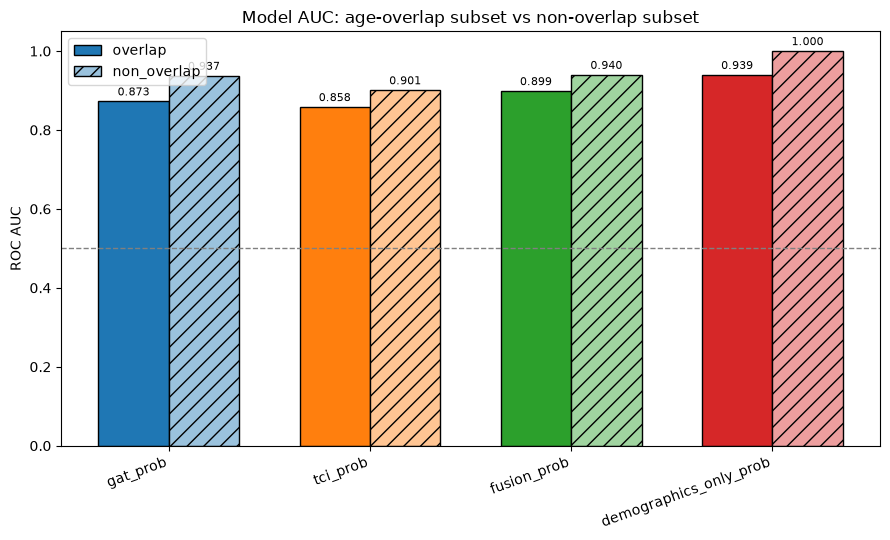

In [7]:
print("=" * 70)
print("SECTION 6a: AUC BAR CHART (overlap vs non_overlap)")
print("=" * 70)

import matplotlib.colors as mcolors

models_order = list(comparison_table.index)
base_color_map = {
    "gat_prob": "#1f77b4",
    "tci_prob": "#ff7f0e",
    "fusion_prob": "#2ca02c",
    "demographics_only_prob": "#d62728",
}

def lighten(hex_color, amount=0.55):
    c = np.array(mcolors.to_rgb(hex_color))
    white = np.array([1, 1, 1])
    return tuple(c + (white - c) * amount)

x = np.arange(len(models_order))
width = 0.35

overlap_vals = comparison_table["overlap_auc"].values
non_overlap_vals = comparison_table["non_overlap_auc"].values

dark_colors = [base_color_map[m] for m in models_order]
light_colors = [lighten(base_color_map[m]) for m in models_order]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(x - width / 2, overlap_vals, width, label="overlap",
       color=dark_colors, edgecolor="black")
ax.bar(x + width / 2, non_overlap_vals, width, label="non_overlap",
       color=light_colors, edgecolor="black", hatch="//")

ax.set_xticks(x)
ax.set_xticklabels(models_order, rotation=20, ha="right")
ax.set_ylabel("ROC AUC")
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_title("Model AUC: age-overlap subset vs non-overlap subset")
ax.legend()

for xi, v in zip(x - width / 2, overlap_vals):
    if not np.isnan(v):
        ax.text(xi, v + 0.015, f"{v:.3f}", ha="center", fontsize=8)
for xi, v in zip(x + width / 2, non_overlap_vals):
    if not np.isnan(v):
        ax.text(xi, v + 0.015, f"{v:.3f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "age_overlap_auc_barchart.png", dpi=150)
plt.show()

SECTION 6b: AGE vs FUSION_PROB SCATTER (overlap range shaded)


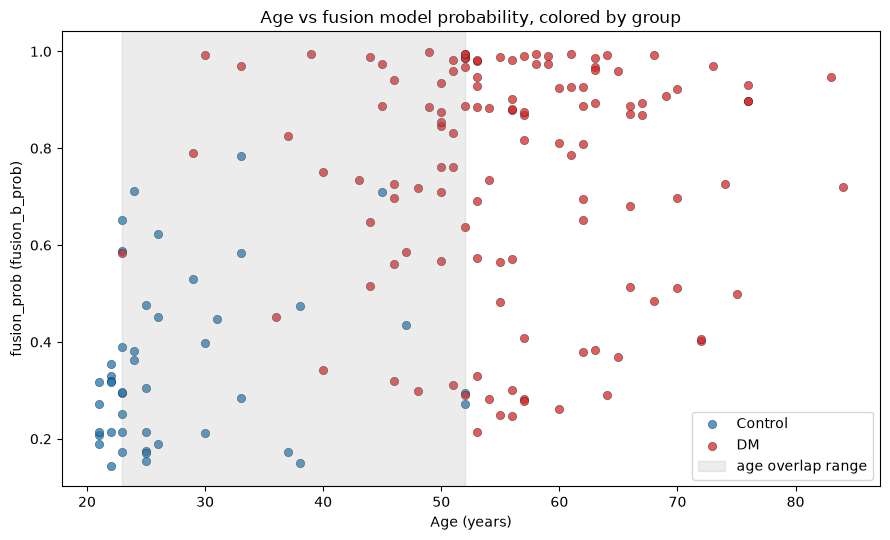

In [8]:
print("=" * 70)
print("SECTION 6b: AGE vs FUSION_PROB SCATTER (overlap range shaded)")
print("=" * 70)

fig, ax = plt.subplots(figsize=(9, 5.5))

group_colors = {"Control": "#1f77b4", "DM": "#d62728"}
for grp, color in group_colors.items():
    sub = df[df["group"] == grp]
    ax.scatter(sub["Age_years"], sub["fusion_prob"], label=grp, color=color,
               alpha=0.75, edgecolor="black", linewidth=0.3)

ax.axvspan(overlap_min, overlap_max, color="gray", alpha=0.15, label="age overlap range")

ax.set_xlabel("Age (years)")
ax.set_ylabel("fusion_prob (fusion_b_prob)")
ax.set_title("Age vs fusion model probability, colored by group")
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "age_overlap_scatter.png", dpi=150)
plt.show()

## Section 7 — Qualitative Summary

The cell below builds this summary directly from the Section 4 comparison table and
the Section 2 sample-size warning, so it reflects the actual numbers whenever the
notebook is run.

In [9]:
demo_overlap_auc = comparison_table.loc["demographics_only_prob", "overlap_auc"]
demo_non_overlap_auc = comparison_table.loc["demographics_only_prob", "non_overlap_auc"]
demo_drop = (
    demo_non_overlap_auc - demo_overlap_auc
    if not (np.isnan(demo_overlap_auc) or np.isnan(demo_non_overlap_auc))
    else np.nan
)

thermal_models = ["gat_prob", "tci_prob", "fusion_prob"]
thermal_drops = {}
for m in thermal_models:
    ov = comparison_table.loc[m, "overlap_auc"]
    non = comparison_table.loc[m, "non_overlap_auc"]
    thermal_drops[m] = (non - ov) if not (np.isnan(ov) or np.isnan(non)) else np.nan

lines = []
lines.append(f"**Overlap subset size:** n={n_overlap_total} ({n_overlap_classes} class(es) present).\n")

if underpowered:
    lines.append(
        "> **Caution:** the overlap subset is small / underpowered (per the Section 2 "
        "warning); treat the AUC point estimates below as suggestive, not conclusive.\n"
    )

if not np.isnan(demo_drop):
    lines.append(
        f"- `demographics_only_prob` AUC: **{demo_overlap_auc:.3f}** (overlap) vs "
        f"**{demo_non_overlap_auc:.3f}** (non-overlap) -- a drop of **{demo_drop:.3f}** "
        f"on the harder, age-matched subset.\n"
    )
else:
    lines.append("- `demographics_only_prob` AUC could not be compared (NaN in one subset).\n")

for m in thermal_models:
    ov = comparison_table.loc[m, "overlap_auc"]
    non = comparison_table.loc[m, "non_overlap_auc"]
    drop = thermal_drops[m]
    if not np.isnan(drop):
        lines.append(
            f"- `{m}` AUC: **{ov:.3f}** (overlap) vs **{non:.3f}** (non-overlap) -- "
            f"drop of **{drop:.3f}**.\n"
        )
    else:
        lines.append(f"- `{m}` AUC could not be compared (NaN in one subset).\n")

held_up_better = []
if not np.isnan(demo_drop):
    held_up_better = [m for m in thermal_models
                       if not np.isnan(thermal_drops[m]) and thermal_drops[m] < demo_drop]
    lines.append(
        "\n**Models whose AUC dropped less than the demographics-only baseline on the "
        f"overlap subset:** {', '.join(held_up_better) if held_up_better else 'none'}.\n"
    )

if underpowered:
    verdict = "INCONCLUSIVE -- overlap subset too small / missing a class (see Section 2 warning)"
elif np.isnan(demo_drop):
    verdict = "INCONCLUSIVE -- demographics-only AUC not computable in one subset"
elif len(held_up_better) > 0:
    verdict = "Thermal signal holds up better than the demographics-only baseline on the hard subset"
else:
    verdict = "Thermal signal does NOT clearly hold up better than the demographics-only baseline"

lines.append(f"\n**Headline read:** {verdict}\n")

display(Markdown("\n".join(lines)))

**Overlap subset size:** n=79 (2 class(es) present).

- `demographics_only_prob` AUC: **0.939** (overlap) vs **1.000** (non-overlap) -- a drop of **0.061** on the harder, age-matched subset.

- `gat_prob` AUC: **0.873** (overlap) vs **0.937** (non-overlap) -- drop of **0.065**.

- `tci_prob` AUC: **0.858** (overlap) vs **0.901** (non-overlap) -- drop of **0.043**.

- `fusion_prob` AUC: **0.899** (overlap) vs **0.940** (non-overlap) -- drop of **0.041**.


**Models whose AUC dropped less than the demographics-only baseline on the overlap subset:** tci_prob, fusion_prob.


**Headline read:** Thermal signal holds up better than the demographics-only baseline on the hard subset


## Section 8 — Save Results

- `results/age_overlap_validation.csv` — 167 rows: `subject_id, group, Age_years,
  overlap_flag, gat_prob, tci_prob, fusion_prob, demographics_only_prob`
- `results/age_overlap_summary.json` — the Section 4 comparison table and Section 5's
  within-overlap age-gap stats.

In [10]:
print("=" * 70)
print("SECTION 8: SAVE RESULTS")
print("=" * 70)

out_csv = df[["subject_id", "group", "Age_years", "overlap_flag",
              "gat_prob", "tci_prob", "fusion_prob", "demographics_only_prob"]]
csv_path = RESULTS_DIR / "age_overlap_validation.csv"
out_csv.to_csv(csv_path, index=False)
print(f"Saved {len(out_csv)} rows to {csv_path}")

summary = {
    "comparison_table": comparison_table.reset_index().to_dict(orient="records"),
    "within_overlap_age_stats": {
        "Control": {
            "n": int(len(control_ages_ov)),
            "mean": float(control_ages_ov.mean()) if len(control_ages_ov) else None,
            "std": float(control_ages_ov.std()) if len(control_ages_ov) else None,
            "min": float(control_ages_ov.min()) if len(control_ages_ov) else None,
            "max": float(control_ages_ov.max()) if len(control_ages_ov) else None,
        },
        "DM": {
            "n": int(len(dm_ages_ov)),
            "mean": float(dm_ages_ov.mean()) if len(dm_ages_ov) else None,
            "std": float(dm_ages_ov.std()) if len(dm_ages_ov) else None,
            "min": float(dm_ages_ov.min()) if len(dm_ages_ov) else None,
            "max": float(dm_ages_ov.max()) if len(dm_ages_ov) else None,
        },
        "mannwhitney_u": float(u_stat) if not np.isnan(u_stat) else None,
        "mannwhitney_p": float(p_value) if not np.isnan(p_value) else None,
    },
    "overlap_age_range": {"min": float(overlap_min), "max": float(overlap_max)},
    "overlap_subset_n": int(n_overlap_total),
    "overlap_subset_classes_present": int(n_overlap_classes),
    "underpowered_warning": bool(underpowered),
}

json_path = RESULTS_DIR / "age_overlap_summary.json"
with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"Saved summary JSON to {json_path}")

SECTION 8: SAVE RESULTS
Saved 167 rows to results\age_overlap_validation.csv
Saved summary JSON to results\age_overlap_summary.json


## Section 9 — Final Summary

In [11]:
print("=" * 70)
print("SECTION 9: FINAL SUMMARY")
print("=" * 70)

print("\nComparison table (overlap vs non_overlap AUC):")
print(comparison_table.round(4))

print(f"\nHeadline finding: {verdict}")

issues = []
if underpowered:
    issues.append(f"Overlap subset underpowered: n={n_overlap_total}, classes present={n_overlap_classes}")
if df["demographics_only_prob"].isna().sum() > 0:
    issues.append(f"{df['demographics_only_prob'].isna().sum()} subjects have NaN "
                  f"demographics_only_prob (missing BMI)")
if comparison_table.isna().any().any():
    issues.append("One or more AUC values could not be computed (NaN in comparison table) -- see warnings above")

if issues:
    print(f"\nIssues found ({len(issues)}):")
    for i, issue in enumerate(issues, 1):
        print(f"  {i}. {issue}")
else:
    print("\n0 issues found.")

print("\nOutput files saved:")
print(f"  - {csv_path}")
print(f"  - {json_path}")

SECTION 9: FINAL SUMMARY

Comparison table (overlap vs non_overlap AUC):
                        overlap_auc  overlap_n  non_overlap_auc  non_overlap_n
model                                                                         
gat_prob                     0.8725         79           0.9374             88
tci_prob                     0.8582         79           0.9008             88
fusion_prob                  0.8987         79           0.9398             88
demographics_only_prob       0.9395         69           1.0000             71

Headline finding: Thermal signal holds up better than the demographics-only baseline on the hard subset

Issues found (1):
  1. 27 subjects have NaN demographics_only_prob (missing BMI)

Output files saved:
  - results\age_overlap_validation.csv
  - results\age_overlap_summary.json
